In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
df = pd.read_csv('Customer Churn.csv')

In [15]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


# replacing blanks with 0 as tenure is 0 and no total charges are recorded

In [17]:
df["TotalCharges"] = df["TotalCharges"].replace(" ","0")
df["TotalCharges"] = df["TotalCharges"].astype("float")

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [23]:
df.isnull().sum().sum()

np.int64(0)

In [24]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [26]:
df["customerID"].duplicated().sum()

np.int64(0)

#Converted 0 and 1 values of senior citizen to yes/no to make it easier to understand

In [27]:
def conv(value):
    if value == 1:
        return "yes"
    else:
        return "no"

df['SeniorCitizen'] = df["SeniorCitizen"].apply(conv)

In [29]:
df.head(35)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,no,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,no,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,no,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,no,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,no,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,no,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,Yes
6,1452-KIOVK,Male,no,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.40,No
7,6713-OKOMC,Female,no,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.90,No
8,7892-POOKP,Female,no,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,no,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


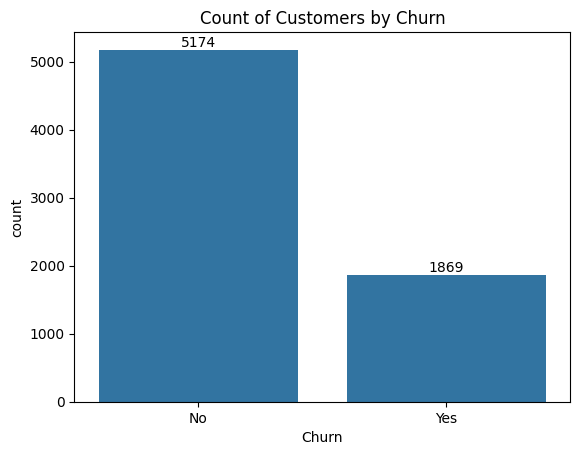

In [41]:
ax = sns.countplot(x ='Churn', data = df)

ax.bar_label(ax.containers[0])
plt.title("Count of Customers by Churn")
plt.show()

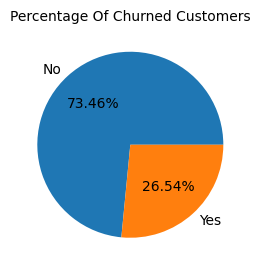

In [44]:
plt.figure(figsize = (3,4))
gb = df.groupby("Churn").agg({'Churn':"count"})
plt.pie(gb['Churn'] , labels= gb.index, autopct = "%1.2f%%")
plt.title("Percentage Of Churned Customers", fontsize=10)
plt.show()

#form the given pie chart we can conclude that 26.54% of our customers have churned out.#now let's explore reason behind it

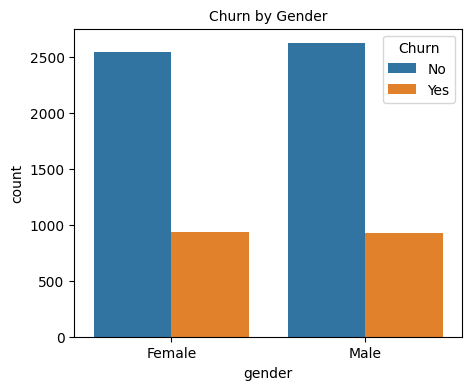

In [53]:
plt.figure(figsize=(5,4))
sns.countplot(x ="gender",data = df , hue= "Churn")
plt.title("Churn by Gender", fontsize=10 )
plt.show()

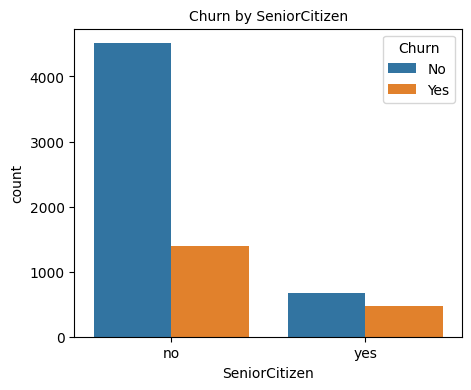

In [55]:
plt.figure(figsize=(5,4))
sns.countplot(x ="SeniorCitizen",data = df , hue= "Churn")
plt.title("Churn by SeniorCitizen", fontsize=10 )
plt.show()

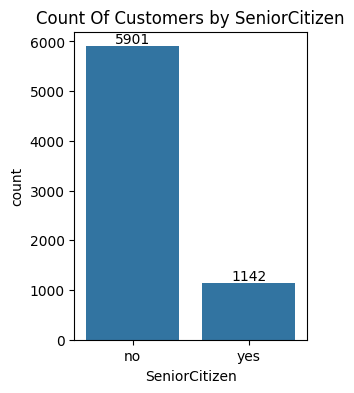

In [73]:
plt.figure(figsize=(3,4))
ax =sns.countplot(x ="SeniorCitizen",data = df)
ax.bar_label(ax.containers[0])
plt.title("Count Of Customers by SeniorCitizen")
plt.show()

<Figure size 800x800 with 0 Axes>

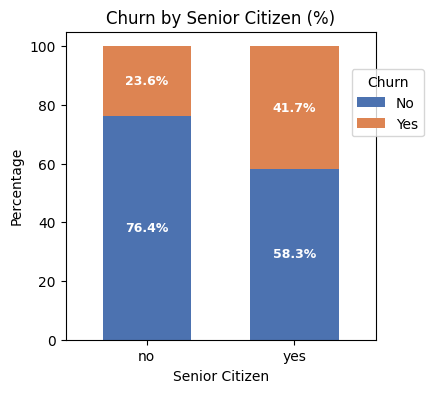

In [76]:


plt.figure(figsize=(8,8))
# Create a crosstab
ct = pd.crosstab(df['SeniorCitizen'], df['Churn'])

# Convert counts to percentages
ct_percent = ct.div(ct.sum(axis=1), axis=0) * 100

# Plot 100% stacked bar chart
ax = ct_percent.plot(
    kind='bar',
    stacked=True,
    figsize=(4,4),
    color=['#4C72B0', '#DD8452'],
    width=0.6
)

# Add percentage labels
for container in ax.containers:
    labels = [
        f'{bar.get_height():.1f}%' if bar.get_height() > 0 else ''
        for bar in container
    ]
    ax.bar_label(
        container,
        labels=labels,
        label_type='center',
        fontsize=9,
        color='white',
        fontweight='bold'
    )

# Titles and labels
plt.title("Churn by Senior Citizen (%)", fontsize=12)
plt.xlabel("Senior Citizen")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.yticks(range(0, 101, 20))

# Legend at the top-left
ax.legend(
    title="Churn",
    bbox_to_anchor =(0.9,0.9),
    frameon=True
)


plt.show()

#Comparatively a greated percentage of people in senior citizen category have churned.

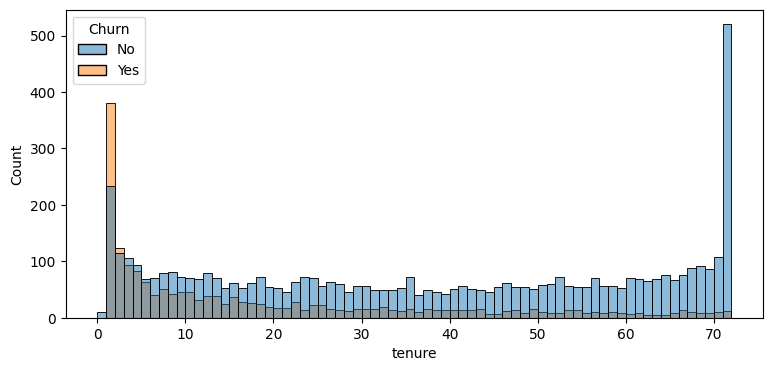

In [79]:
plt.figure(figsize = (9,4))
sns.histplot(x= "tenure" , data = df  , bins=72 , hue= "Churn")
plt.show()

#people who have used our services for a long time have stayed and people who have used our services # 1 or 2 months have Churned

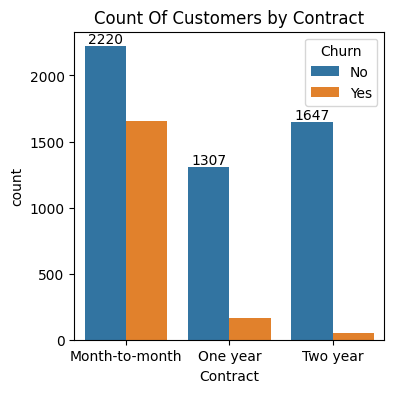

In [83]:
plt.figure(figsize=(4,4))
ax =sns.countplot(x ="Contract",data = df , hue = "Churn")
ax.bar_label(ax.containers[0])
plt.title("Count Of Customers by Contract")
plt.show()

#people who have month to month contract are likely to churn then from those who have 1 or 3 years contract.

In [84]:
df.columns.values

array(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges',
       'TotalCharges', 'Churn'], dtype=object)

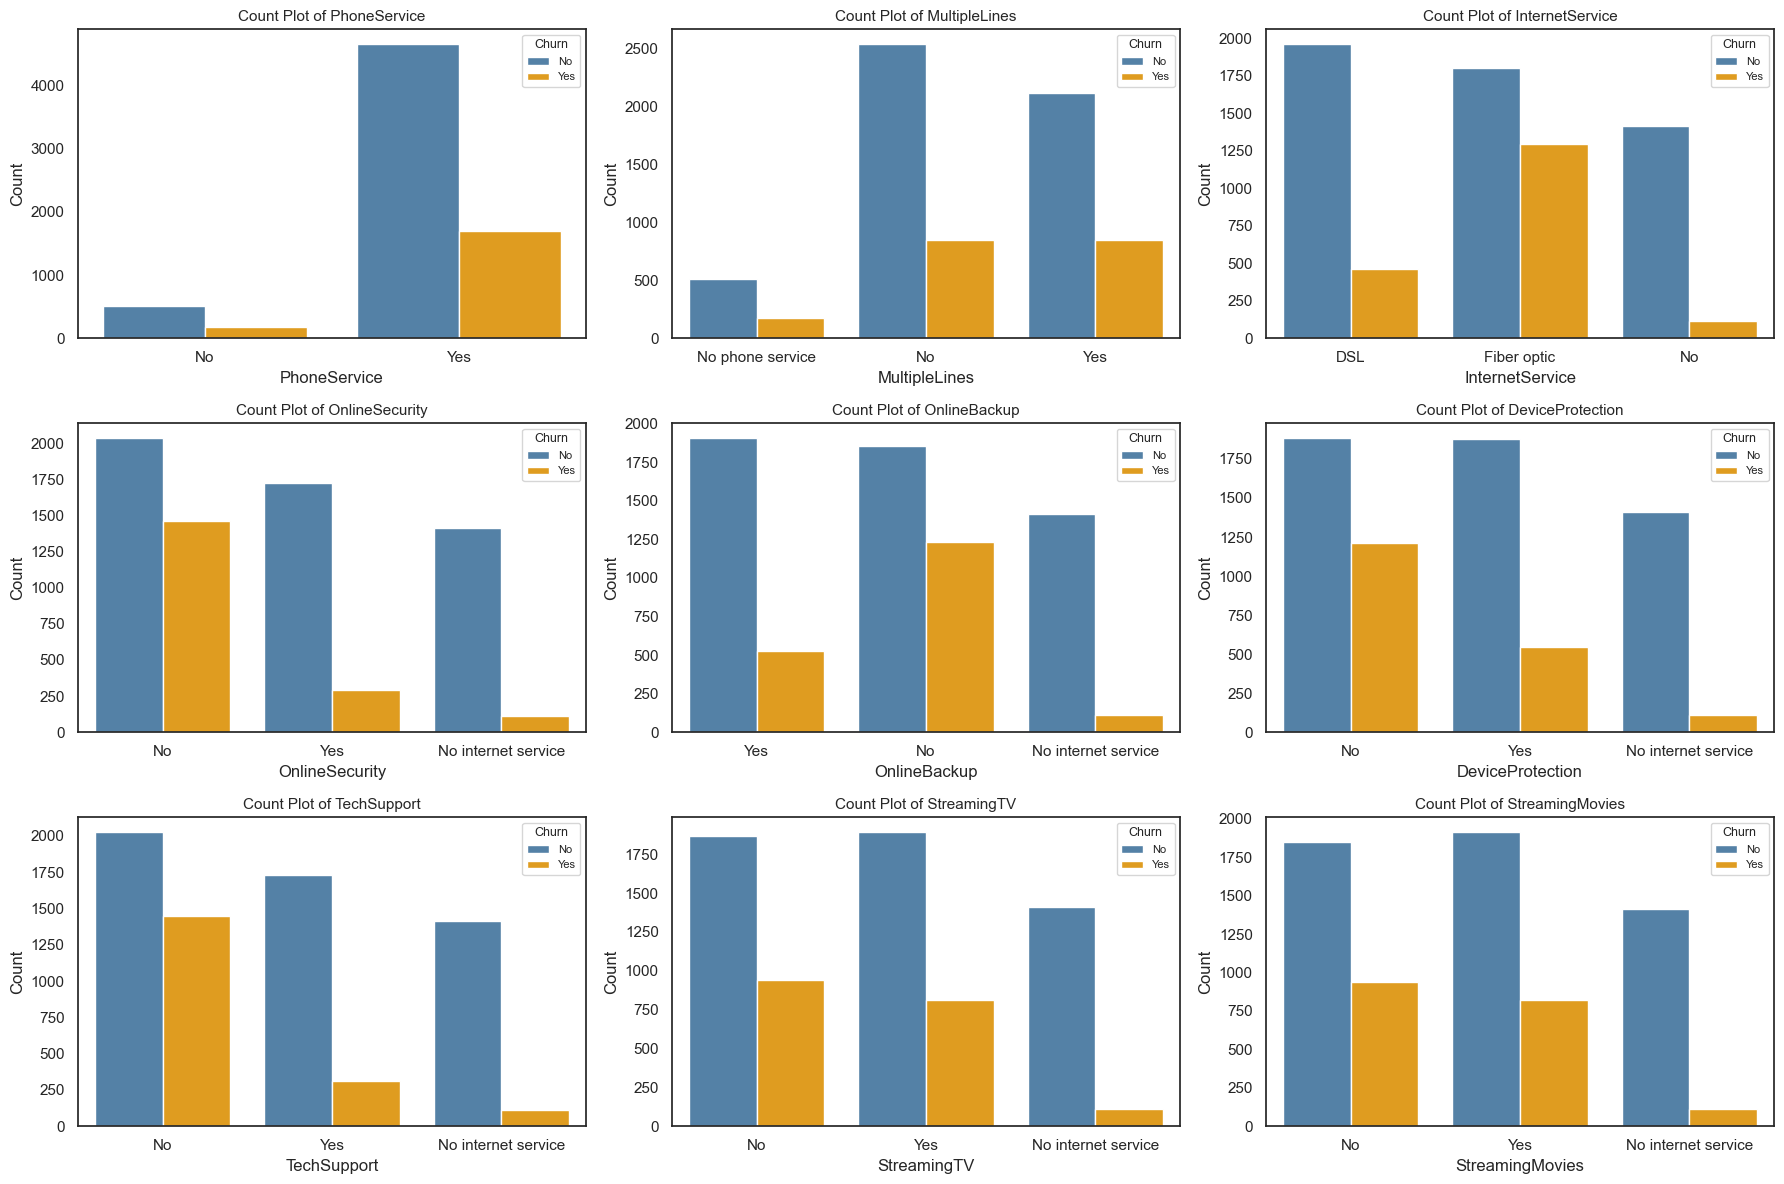

In [100]:

sns.set(style="white")

features = [
    'PhoneService',
    'MultipleLines',
    'InternetService',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]

fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(18, 12))
axes = axes.ravel()

for i, feature in enumerate(features):
    sns.countplot(
        data=df,
        x=feature,
        hue='Churn',
        palette=['steelblue', 'orange'],
        ax=axes[i]
    )

    axes[i].set_title(f'Count Plot of {feature}', fontsize=11)
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Count')
    axes[i].tick_params(axis='x', labelrotation=0)
    axes[i].legend(title='Churn', fontsize=8, title_fontsize=9)

plt.tight_layout()
plt.show()

# The count plots show that customers without Online Security, Online Backup, and Tech Support have noticeably higher churn rates compared to those who use these services. Customers with Fiber Optic internet also exhibit the highest churn among internet service types. In contrast, Phone Service, Multiple Lines, Streaming TV, and Streaming Movies have a relatively smaller impact on churn, as both churned and retained customers are distributed more evenly. Overall, value-added support and security services appear to play a significant role in improving customer retention.

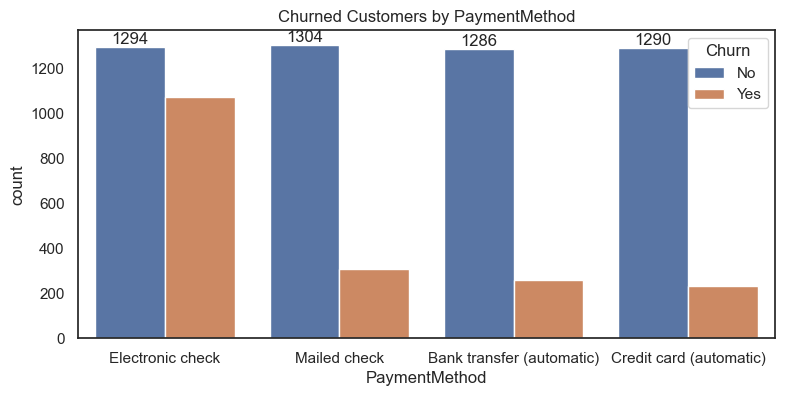

In [105]:

plt.figure(figsize=(9,4))
ax =sns.countplot(x ="PaymentMethod",data = df , hue = "Churn")
ax.bar_label(ax.containers[0])
plt.title("Churned Customers by PaymentMethod")
plt.show()

# Customer is likely to churn when he is using electronic check as a Payment Method.